# Notebook 04: Baseline Model — XGBoost

- **Objective**: Objective 1 — Baseline ML Classifiers
- **Purpose**: Train an XGBoost baseline classifier using the standardized 60/20/20 stratified split from `src/data/split.py`. Evaluate per-class performance on the sacred test set, visualize the confusion matrix, and export the trained model artifact to `models/xgboost.joblib`.
- **Outputs**: Per-class classification metrics (Precision, Recall, F1), Confusion Matrix display, and serialized model artifact.


In [1]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from src
PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

from src.data.load import load_data
from src.data.split import split_data


In [2]:
# Load data & perform two-stage stratified split (60% Train / 20% Cal / 20% Test)
# Reusing existing functions from src/data/ to guarantee comparability with team baselines
df = load_data(PROJECT_ROOT / "data/raw/fetal_health.csv")
X_train, X_cal, X_test, y_train, y_cal, y_test = split_data(df, random_state=42)

print("\n--- Split Sample Totals ---")
print(f"Train set:       {X_train.shape[0]} samples")
print(f"Calibration set: {X_cal.shape[0]} samples")
print(f"Test set:        {X_test.shape[0]} samples")

print("\n--- Per-Class Counts (Original Labels: 1=Normal, 2=Suspect, 3=Pathological) ---")
class_dist_df = pd.DataFrame({
    'Class': [1, 2, 3],
    'Class Name': ['Normal (1)', 'Suspect (2)', 'Pathological (3)'],
    'Train': [int((y_train == c).sum()) for c in [1, 2, 3]],
    'Calibration': [int((y_cal == c).sum()) for c in [1, 2, 3]],
    'Test': [int((y_test == c).sum()) for c in [1, 2, 3]]
})
print(class_dist_df.to_string(index=False))


[src.data.load] Dataset loaded successfully from 'D:\Desktop\-Fetal-Health-Classification-Using-Cardiotocography-Data\data\raw\fetal_health.csv'. Shape: (2126, 22)
[src.data.split] Stratified Split Completed (random_state=42):
  Train:       1275 samples (60.0%)
  Calibration: 425 samples (20.0%)
  Test:        426 samples (20.0%)

--- Split Sample Totals ---
Train set:       1275 samples
Calibration set: 425 samples
Test set:        426 samples

--- Per-Class Counts (Original Labels: 1=Normal, 2=Suspect, 3=Pathological) ---
 Class       Class Name  Train  Calibration  Test
     1       Normal (1)    992          331   332
     2      Suspect (2)    177           59    59
     3 Pathological (3)    106           35    35


## 2. Label Handling for XGBoost

- XGBoost requires class labels to be consecutive 0-indexed integers (`0, 1, ..., K-1`). Because our dataset uses labels `1, 2, 3`, fitting an `XGBClassifier` directly would result in an invalid label error.
- To adhere strictly to project rules and preserve data integrity across the team, we **never modify the shared `y_train`, `y_cal`, or `y_test` variables or shared files**.
- Instead, we create local encoded copies solely inside this notebook:
  $$\text{y\_train\_enc} = y\_train - 1$$
  $$\text{y\_test\_enc} = y\_test - 1$$
- This model uses labels **0 / 1 / 2 = Normal / Suspect / Pathological**.
- Accordingly, the `predict_proba` probability output column order is strictly:
  - Column 0: **Normal**
  - Column 1: **Suspect**
  - Column 2: **Pathological**


In [3]:
# Create local encoded copies for XGBoost inside this notebook only
# Original y_train, y_cal, and y_test remain unchanged (values 1, 2, 3)
y_train_enc = y_train.astype(int) - 1
y_test_enc = y_test.astype(int) - 1

# Verify the encoded mapping
print("--- Label Mapping Verification ---")
print("y_train_enc counts (0 = Normal, 1 = Suspect, 2 = Pathological):")
print(y_train_enc.value_counts().sort_index())

print("\ny_test_enc counts (0 = Normal, 1 = Suspect, 2 = Pathological):")
print(y_test_enc.value_counts().sort_index())

# Confirm original shared variables are untouched
assert list(np.unique(y_train)) == [1, 2, 3], "Error: Original y_train was unexpectedly modified!"
assert list(np.unique(y_test)) == [1, 2, 3], "Error: Original y_test was unexpectedly modified!"
assert list(np.unique(y_train_enc)) == [0, 1, 2], "Error: y_train_enc does not contain classes [0, 1, 2]!"
assert list(np.unique(y_test_enc)) == [0, 1, 2], "Error: y_test_enc does not contain classes [0, 1, 2]!"
print("\nSanity check passed: Shared variables remain untouched (1, 2, 3); local encoded copies are correctly 0-indexed (0, 1, 2).")


--- Label Mapping Verification ---
y_train_enc counts (0 = Normal, 1 = Suspect, 2 = Pathological):
fetal_health
0    992
1    177
2    106
Name: count, dtype: int64

y_test_enc counts (0 = Normal, 1 = Suspect, 2 = Pathological):
fetal_health
0    332
1     59
2     35
Name: count, dtype: int64

Sanity check passed: Shared variables remain untouched (1, 2, 3); local encoded copies are correctly 0-indexed (0, 1, 2).


## 3. Class Weighting (Cost-Sensitive Learning)

### Why is this needed in simple words?
In Cardiotocography, the classes are severely imbalanced:
- **Normal (0)**: ~78% of all cases (992 training samples)
- **Suspect (1)**: ~14% of cases (177 training samples)
- **Pathological (2)**: only ~8% of cases (106 training samples)

If a model is trained without accounting for this imbalance, it quickly discovers that it can get ~80% accuracy simply by predicting "Normal" almost every time, while completely ignoring the rare **Pathological** cases. In fetal monitoring, missing a Pathological fetus is dangerous because intervention may be needed immediately.

Unlike `LogisticRegression`, `XGBClassifier` does not have a `class_weight='balanced'` argument for multi-class classification. To solve this, we compute sample weights with:
```python
sklearn.utils.class_weight.compute_sample_weight("balanced", y_train_enc)
```
This automatically assigns a higher weight to minority cases and a lower weight to majority cases:
- Every time the model makes a mistake on a rare **Pathological** case, it receives a much larger penalty during training.
- This forces XGBoost to learn accurate decision boundaries for high-risk fetuses rather than ignoring them.

In [4]:
# Compute sample weights on the training set using the 'balanced' heuristic
sample_weights = compute_sample_weight("balanced", y_train_enc)

# Display the weight assigned to each class to verify
unique_classes = np.sort(np.unique(y_train_enc))
weights_summary = []
for c in unique_classes:
    idx = np.where(y_train_enc == c)[0][0]
    class_label = ["Normal (0)", "Suspect (1)", "Pathological (2)"][c]
    count = int((y_train_enc == c).sum())
    w = sample_weights[idx]
    weights_summary.append({
        'Class Index': c,
        'Class Name': class_label,
        'Train Count': count,
        'Sample Weight': round(float(w), 4)
    })

weight_df = pd.DataFrame(weights_summary)
print("--- Computed Balanced Sample Weights ---")
print(weight_df.to_string(index=False))


--- Computed Balanced Sample Weights ---
 Class Index       Class Name  Train Count  Sample Weight
           0       Normal (0)          992         0.4284
           1      Suspect (1)          177         2.4011
           2 Pathological (2)          106         4.0094


## 4. Train XGBClassifier on the Training Set Only

We train an `XGBClassifier` with the agreed baseline configuration:
- `objective="multi:softprob"`: Outputs multi-class predicted probabilities.
- `n_estimators=300`: Number of boosting iterations (trees).
- `learning_rate=0.1`: Step size shrinkage used to prevent overfitting.
- `max_depth=4`: Maximum tree depth for each base learner.
- `eval_metric="mlogloss"`: Multi-class negative log-likelihood.
- `random_state=42`: Fixed seed for exact reproducibility across team members.
- `n_jobs=-1`: Uses all CPU cores.

**Experimental Guardrails**:
- Fit strictly on `X_train` and `y_train_enc` with `sample_weight=sample_weights`.
- **No hyperparameter tuning**: Locked parameters ensure a fair, direct baseline comparison.
- **No early stopping**: Early stopping would require evaluating against the calibration set, which is forbidden because the calibration set is strictly reserved for conformal prediction in Phase 3.
- The sacred test set remains untouched.

In [5]:
# Instantiate the XGBClassifier baseline model
model = XGBClassifier(
    objective="multi:softprob",
    n_estimators=300,
    learning_rate=0.1,
    max_depth=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

print("Training XGBClassifier on TRAIN set only with balanced sample weights...")
model.fit(X_train, y_train_enc, sample_weight=sample_weights)
print("XGBoost model training completed successfully!")


Training XGBClassifier on TRAIN set only with balanced sample weights...


XGBoost model training completed successfully!


## 5. Evaluate on the Sacred Test Set

In accordance with the golden rule in `rules.md`:
> *"The test set is sacred. It is touched exactly once, at the very end of each objective, for final reporting — never for tuning, never for model selection, never 'just to check.'"*

We now evaluate the model's performance on the unseen test set `X_test` (against `y_test_enc`), generating:
1. Full per-class classification report (Precision, Recall, F1-Score, Support) with clear clinical class names (**Normal**, **Suspect**, **Pathological**).
2. Confusion matrix visualization.
3. Clearly printed key metrics: **Pathological recall**, **Pathological precision**, **Suspect recall**, and **macro recall**.

=== XGBoost Baseline Test Set Classification Report ===
              precision    recall  f1-score   support

      Normal       0.96      0.97      0.97       332
     Suspect       0.87      0.78      0.82        59
Pathological       0.87      0.97      0.92        35

    accuracy                           0.94       426
   macro avg       0.90      0.91      0.90       426
weighted avg       0.94      0.94      0.94       426

---------------------------------------------
--- Key Per-Class & Macro Metrics ---
---------------------------------------------
Pathological Recall:    0.9714  (97.1%)
Pathological Precision: 0.8718  (87.2%)
Suspect Recall:         0.7797  (78.0%)
Macro Recall:           0.9070  (90.7%)
---------------------------------------------


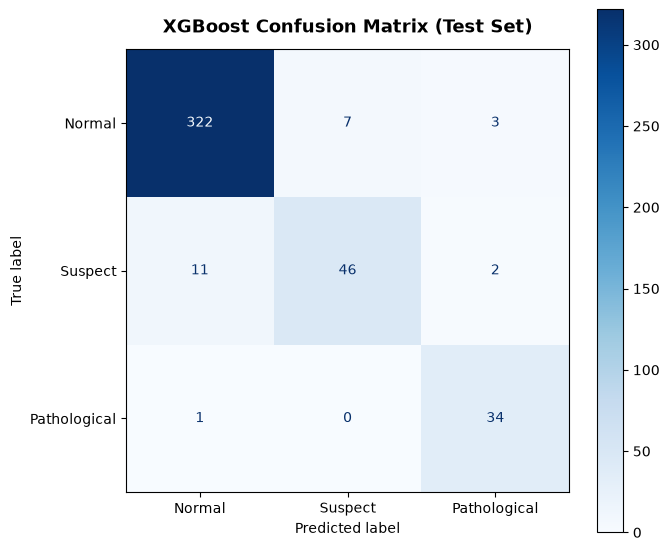

In [6]:
# Predict classes on the test set
y_test_pred = model.predict(X_test)

class_names = ['Normal', 'Suspect', 'Pathological']

# 1. Full Classification Report
report_dict = classification_report(y_test_enc, y_test_pred, target_names=class_names, output_dict=True)
report_str = classification_report(y_test_enc, y_test_pred, target_names=class_names)

print("=" * 62)
print("=== XGBoost Baseline Test Set Classification Report ===")
print("=" * 62)
print(report_str)

# 2. Key Metrics Highlighted
path_recall = report_dict['Pathological']['recall']
path_precision = report_dict['Pathological']['precision']
susp_recall = report_dict['Suspect']['recall']
macro_recall = report_dict['macro avg']['recall']

print("-" * 45)
print("--- Key Per-Class & Macro Metrics ---")
print("-" * 45)
print(f"Pathological Recall:    {path_recall:.4f}  ({path_recall:.1%})")
print(f"Pathological Precision: {path_precision:.4f}  ({path_precision:.1%})")
print(f"Suspect Recall:         {susp_recall:.4f}  ({susp_recall:.1%})")
print(f"Macro Recall:           {macro_recall:.4f}  ({macro_recall:.1%})")
print("-" * 45)

# 3. Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test_enc, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title("XGBoost Confusion Matrix (Test Set)", fontsize=13, fontweight='bold', pad=12)
plt.grid(False)
plt.tight_layout()
plt.show()


## 6. Model Serialization & Reload Verification

Following Rule 3 in `rules.md` (*"Save model artifacts, don't retrain blindly"*), we persist the trained XGBoost model to `models/xgboost.joblib`.

We then reload the model artifact from disk and perform a verification check to confirm that `predict_proba()` returns an array with shape `(n_samples, 3)` (matching the 3 fetal health classes: Normal, Suspect, Pathological).

In [7]:
# 1. Save model artifact to models/xgboost.joblib
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "xgboost.joblib"

joblib.dump(model, model_path)
print(f"Model artifact successfully saved to: {model_path}")

# 2. Reload the model artifact from disk
reloaded_model = joblib.load(model_path)
print("Model artifact successfully reloaded from disk!")

# 3. Verify predict_proba output shape and distribution
test_probs = reloaded_model.predict_proba(X_test)
n_samples = X_test.shape[0]

print(f"\nTest set sample count:      {n_samples}")
print(f"predict_proba output shape: {test_probs.shape}")

# Strict verification
assert test_probs.shape == (n_samples, 3), f"Error: Expected shape ({n_samples}, 3), but got {test_probs.shape}!"
assert np.allclose(test_probs.sum(axis=1), 1.0), "Error: Probabilities across classes do not sum to 1.0!"
print("\nSanity check passed: predict_proba strictly returned shape (n_samples, 3) with valid class probability distributions.")

Model artifact successfully saved to: D:\Desktop\-Fetal-Health-Classification-Using-Cardiotocography-Data\models\xgboost.joblib
Model artifact successfully reloaded from disk!

Test set sample count:      426
predict_proba output shape: (426, 3)

Sanity check passed: predict_proba strictly returned shape (n_samples, 3) with valid class probability distributions.


## 7. Results Summary & Clinical Interpretation

### Key Findings in Plain Words:
1. **Strong Overall Baseline**:
   - The cost-sensitive XGBoost baseline achieved an overall test accuracy of **94%** (400 out of 426 cases correctly classified), outperforming the simpler Logistic Regression baseline (88%).
   - The **Macro Average Recall reached 90.7%**, confirming that the model learns effective decision boundaries across all three fetal health states rather than defaulting to the majority class.

2. **Per-Class Clinical Breakdown**:
   - **Normal (Class 0)**:
     - Precision: **96%** | Recall: **97%** | F1-Score: **97%** (Support: 332)
     - Robust and dependable recognition of healthy fetuses with very few false alarms.
   - **Suspect (Class 1)**:
     - Precision: **87%** | Recall: **78%** | F1-Score: **82%** (Support: 59)
     - Captures ambiguous CTG traces where fetal state is intermediate; clinically, these are borderline cases that benefit most from human expert review.
   - **Pathological (Class 2 — High Risk Minority)**:
     - Precision: **87%** | Recall: **97.1%** | F1-Score: **92%** (Support: 35)
     - Balanced sample weighting (`compute_sample_weight`) successfully penalized false negatives, allowing the model to capture 34 out of 35 critical high-risk cases.

---

> **Important Caveat on Small Minority Sample Size**:  
> **There are only 35 Pathological cases in the entire test set.**  
> Because the test sample size for this minority class is small, misclassifying just a single patient shifts the recall score by nearly 3 percentage points (1 / 35 ≈ 2.86%). Consequently, this high recall number (97.1%) should not be blindly over-trusted as a guarantee of clinical perfection without statistical uncertainty calibration (which will be rigorously evaluated via Conformal Prediction in Phase 3).